# Air Quality

___

## Introduction

Upon the question "What is the best neighborhood in Pittsburgh?", I immediately thought of the basic necessities of life which consist of air, water, food, shelter, and clothing. I first eliminated the food and clothing due to them lacking strong correspondence with the neighborhood. Within the options of air, water, and shelter, I then decided to focus on air because we need it and are surrounded by it continuously. I then branched off the idea of air and searched through potential datasets.

 ## Data Analysis

A top neighborhood should have clean air and in order to acheive this, there should be as many greenery as possible. I used the City of Pittsburgh Trees dataset and it indicates data such as the size and the benefit of the tree under their specific neighborhood. The more and bigger the tree is within a neighborhood, the better the air quality which make it a better neighborhood.

/scratch/slurm-45360/ipykernel_1400744/2539187917.py:5: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  airQuality = pd.read_csv("https://data.wprdc.org/datastore/dump/1515a93c-73e3-4425-9b35-1cd11b2196da",


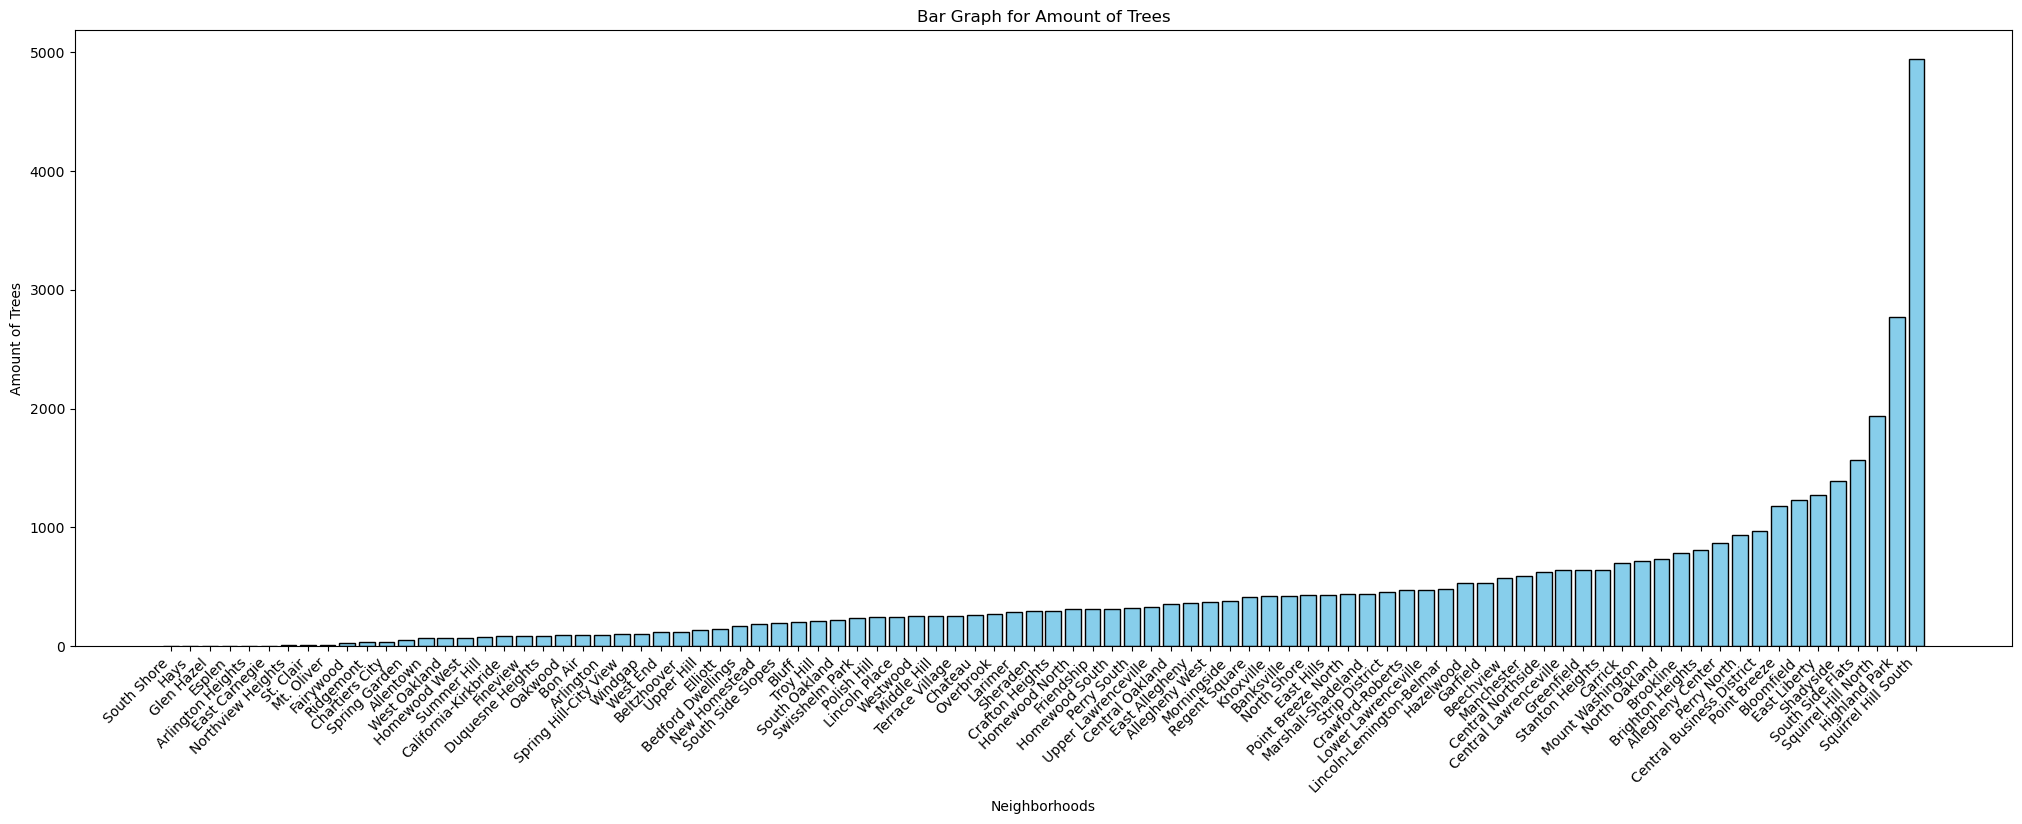

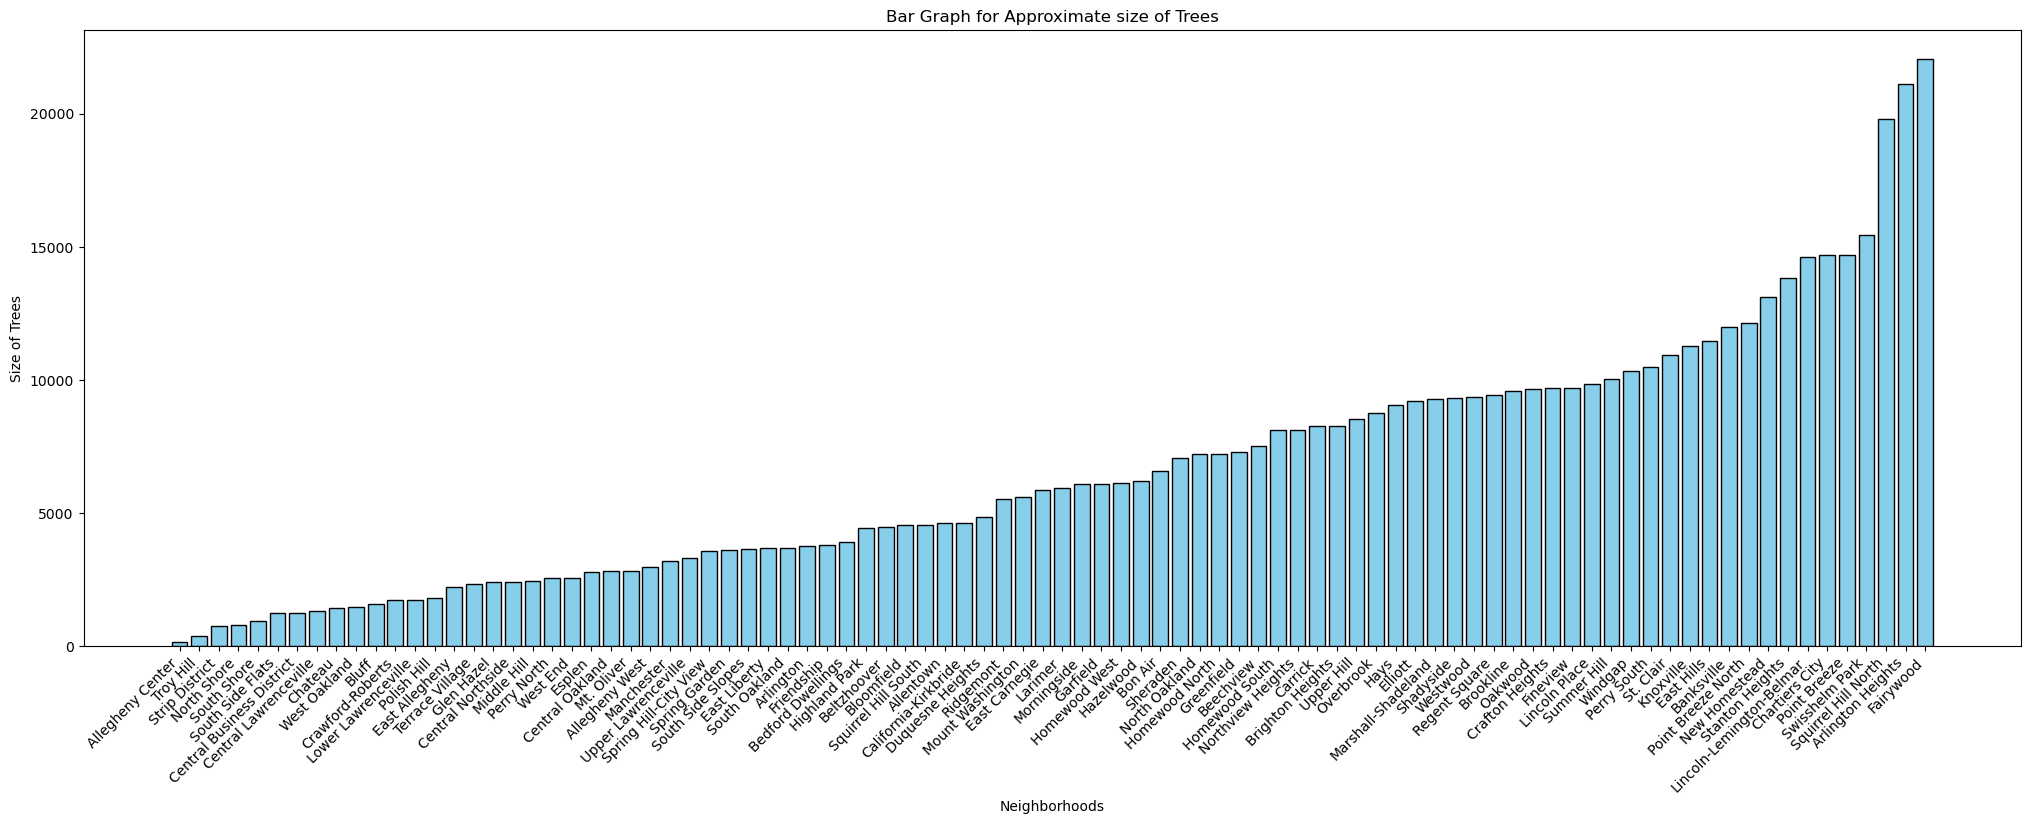

/scratch/slurm-45236/ipykernel_1135433/2539187917.py:5: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  airQuality = pd.read_csv("https://data.wprdc.org/datastore/dump/1515a93c-73e3-4425-9b35-1cd11b2196da",


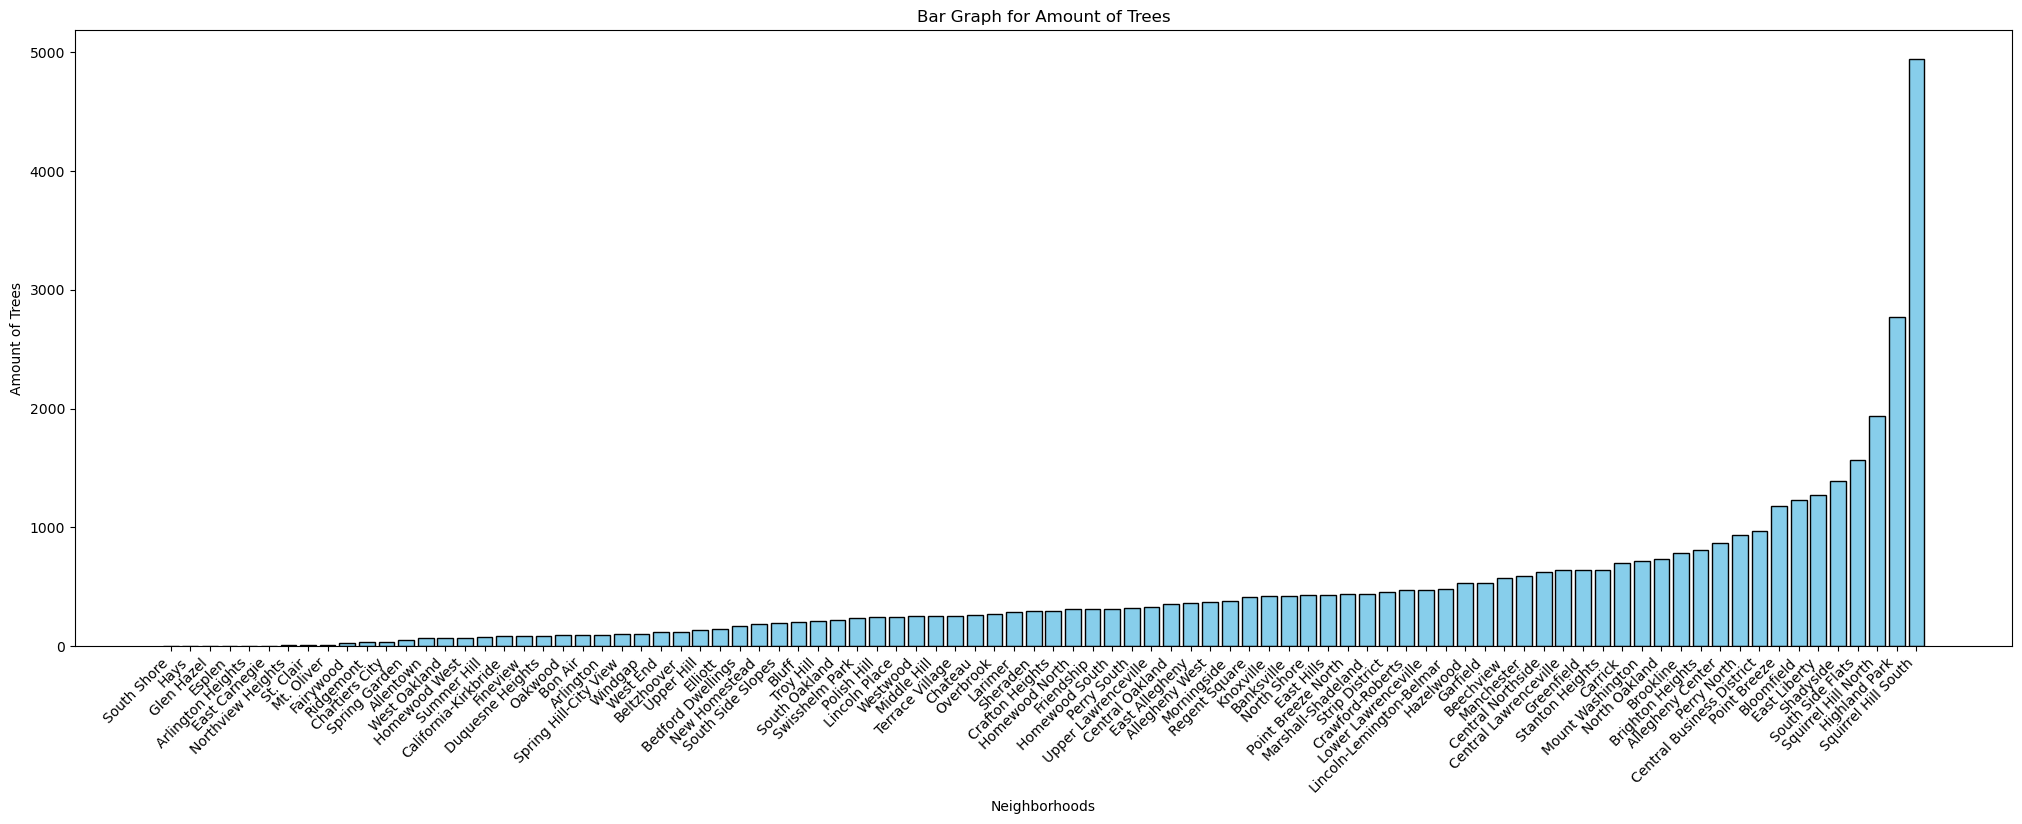

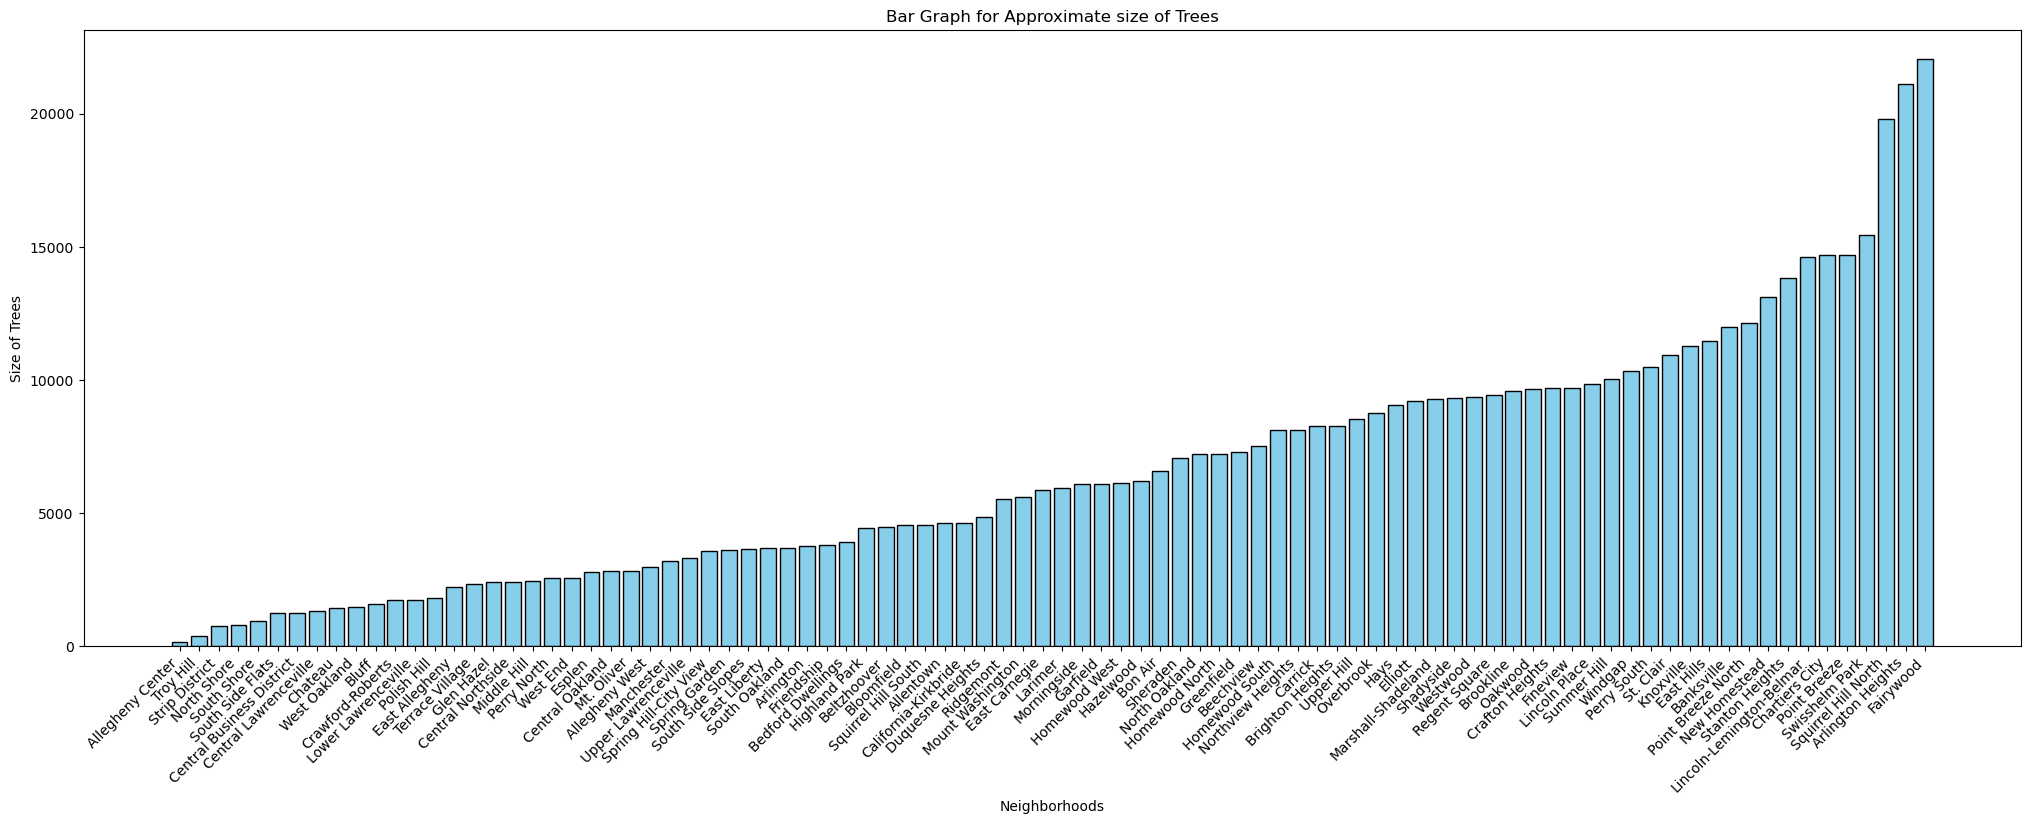

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

airQuality = pd.read_csv("https://data.wprdc.org/datastore/dump/1515a93c-73e3-4425-9b35-1cd11b2196da", 
                           parse_dates=True)
air_dict = {}

for index, row in airQuality.iterrows():
    neighborhood = row['neighborhood']
    height = row['height']
    diameter = row['diameter_base_height']
    volume = np.pi * (diameter / 2)**2 * height
    
    if pd.isna(neighborhood):
        continue
    if pd.isna(height) or pd.isna(diameter):
        continue
    if neighborhood not in air_dict:
        air_dict[neighborhood] = {'volume': volume, 'amount': 1}
    else:
        air_dict[neighborhood]['volume'] += volume
        air_dict[neighborhood]['amount'] += 1
    
neighborhoods = []
volume = []
amount = []

for neighborhood, data in air_dict.items():
    neighborhoods.append(neighborhood)
    volume.append(data['volume'] / data['amount'])
    amount.append(data['amount'])

sort1 = np.argsort(amount)
neighborhoods1 = np.array(neighborhoods)[sort1]
amount = np.array(amount)[sort1]

sort2 = np.argsort(volume)
neighborhoods2 = np.array(neighborhoods)[sort2]
volume = np.array(volume)[sort2]

plt.figure(figsize=(25, 8))
plt.bar(neighborhoods1, amount, color='skyblue', edgecolor='black')
plt.title('Bar Graph for Amount of Trees')
plt.xlabel('Neighborhoods')
plt.ylabel('Amount of Trees')
plt.xticks(rotation=45, ha='right')

plt.figure(figsize=(25, 8))
plt.bar(neighborhoods2, volume, color='skyblue', edgecolor='black')
plt.title('Bar Graph for Approximate size of Trees')
plt.xlabel('Neighborhoods')
plt.ylabel('Size of Trees')
plt.xticks(rotation=45, ha='right')

plt.show()

The two bar graphs show the visuals of the amount and size of the trees within each neighborhood. However, taking over a single metric would not make sense because a neighborhood can have a small amount of large-sized trees so we must combine the two metrics together in a meaningful way.## Conclusion

In [39]:
neighborhoods = []
volume = []
amount = []

for neighborhood, data in air_dict.items():
    neighborhoods.append(neighborhood)
    volume.append(data['volume'] / data['amount'])
    amount.append(data['amount'])

TrueTrue
neighborhoods = []
volume = []
amount = []

for neighborhood, data in air_dict.items():
    neighborhoods.append(neighborhood)
    volume.append(data['volume'] / data['amount'])
    amount.append(data['amount'])

df = pd.DataFrame({'Neighborhood': neighborhoods, 'Volume': volume, 'Amount': amount})
df['rankVolume'] = df['Volume'].rank(ascending=True, method='min')
df['rankAmount'] = df['Amount'].rank(ascending=True, method='min')
df['combine'] = df['rankVolume'] + df['rankAmount']
sortRank = df.sort_values(by='combine', ascending=True)

print(sortRank.tail(3))

           Neighborhood        Volume  Amount  rankVolume  rankAmount  combine
8       Stanton Heights  13842.820686     644        83.0        74.0    157.0
43         Point Breeze  14686.804190    1177        86.0        83.0    169.0
42  Squirrel Hill North  19797.190787    1934        88.0        88.0    176.0


           Neighborhood        Volume  Amount  rankVolume  rankAmount  combine
8       Stanton Heights  13842.820686     644        83.0        74.0    157.0
43         Point Breeze  14686.804190    1177        86.0        83.0    169.0
42  Squirrel Hill North  19797.190787    1934        88.0        88.0    176.0


Taking into consideration both the amount of trees and the size of trees, the top 3 neighborhoods of Pittsburgh are Squirrel Hill North, Point Breeze, and Stanton Heights. My personal favorite neighborhood is Oakland because I really haven't been to the other neighborhood that much yet as I am not from Pittsburgh. However, I am not surprised that Oakland is not ranked amongst the best neighborhoods in Pittsburgh in terms of air quality because it is a very urban area with probably a lot of air pollution.

Taking into consideration both the amount of trees and the size of trees, the top 3 neighborhoods of Pittsburgh are Squirrel Hill North, Point Breeze, and Stanton Heights. My personal favorite neighborhood is Oakland because I really haven't been to the other neighborhood that much yet as I am not from Pittsburgh. However, I am not surprised that Oakland is not ranked amongst the best neighborhoods in Pittsburgh in terms of air quality because it is a very urban area with probably a lot of air pollution.